# Phenix - Détection d'URL atypiques à partir des logs WAF

Ce notebook lit les résultats de `python -m detector.waf train`. Il ne réentraîne pas le modèle et ne charge pas joblib. Les étiquettes proviennent des scénarios synthétiques, pas des règles SIEM. Un score élevé indique une URL atypique, sans prouver une injection SQL réussie.

Placer ce fichier dans `backend/ML/notebooks`. Sélectionner un noyau Python avec pandas, numpy et matplotlib, puis Exécuter tout. Les bibliothèques Docker ne sont pas automatiquement disponibles dans le noyau local.

Le dossier choisi est `local-waf-v1`. Les sorties enregistrées ont été calculées ici sur le jeu synthétique fourni ; relancer pour analyser votre entraînement. Le test reste exclu de cet essai.


In [1]:
from pathlib import Path
import json
from urllib.parse import unquote_plus
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

EXPERIMENT = "local-waf-v1"
roots = [candidate for parent in [Path.cwd(), *Path.cwd().parents]
         for candidate in [parent, parent / "backend" / "ML"]
         if (candidate / "experiments" / EXPERIMENT / "metrics.json").is_file()]
if not roots:
    raise FileNotFoundError("Vérifier EXPERIMENT ; placer le notebook dans backend/ML/notebooks")
EXP_DIR = roots[0] / "experiments" / EXPERIMENT
report = json.loads((EXP_DIR / "metrics.json").read_text(encoding="utf-8"))
assert report["metadata"]["feature_schema"] == "waf-query-shape-v1"
assert "test" not in report["splits"], "Ce notebook est réservé à la validation exploratoire."
threshold = report["metadata"]["threshold"]
print("Expérience :", EXPERIMENT)
print("Seuil fixé sur la calibration normale :", round(threshold, 6))
print("Variables :", ", ".join(report["metadata"]["features"]))


Expérience : local-waf-v1
Seuil fixé sur la calibration normale : 0.638582
Variables : raw_length, decoded_length, percent_count, plus_count, decode_reduction, second_decode_reduction, parameter_count, quote_count, space_count, equals_count, dash_count, slash_count, parenthesis_count, semicolon_count, digit_ratio, punctuation_ratio, non_ascii_ratio, token_count, longest_token, character_entropy


## 1. Résultats par requête

VP : tentative annotée détectée ; FN : tentative manquée ; FP : requête normale signalée ; VN : requête normale non signalée. Les tentatives ne sont pas nécessairement des injections réussies.

La précision et le rappel ne sont pas définis quand leur dénominateur est nul (NaN dans le tableau). Les résultats d'apprentissage et de calibration ne sont pas des évaluations indépendantes.


In [2]:
predictions = {}
rows = []
for name in ["train", "calibration", "validation"]:
    df = pd.read_csv(EXP_DIR / f"{name}_predictions.csv", keep_default_na=False, dtype={"loki_timestamp_ns": str})
    df["observed_at"] = pd.to_datetime(df.observed_at, utc=True)
    assert df.loki_timestamp_ns.is_unique
    y = df.is_attack.eq(1)
    p = df.predicted_anomaly.eq(1)
    assert np.array_equal(p.to_numpy(), (df.anomaly_score > threshold).to_numpy())
    counts = {"true_positive": int((y & p).sum()), "false_positive": int((~y & p).sum()),
              "false_negative": int((y & ~p).sum()), "true_negative": int((~y & ~p).sum())}
    for key, value in counts.items():
        assert report["splits"][name][key] == value, f"Métriques et CSV différents : {name}/{key}"
    s = report["splits"][name]
    rows.append({"Période": name, "Requêtes": len(df), "VP": counts["true_positive"],
                 "FP": counts["false_positive"], "FN": counts["false_negative"], "VN": counts["true_negative"],
                 "Précision": s["precision"], "Rappel": s["recall"], "Taux FP": s["false_positive_rate"]})
    predictions[name] = df
summary = pd.DataFrame(rows).set_index("Période")
display(summary.round(4))


,Requêtes,VP,FP,FN,VN,Précision,Rappel,Taux FP
Période,,,,,,,,
train,6000,0,0,0,6000,NaN,NaN,0.0
calibration,2000,0,0,0,2000,NaN,NaN,0.0
validation,2000,115,0,225,1660,1.0,0.3382,0.0


## 2. Scores et erreurs de validation

La ligne pointillée représente le seuil déjà fixé. Les scores ne sont pas des probabilités et ne se comparent pas directement à ceux des anciens modèles CPU/latence. Les observations sont ordonnées par horodatage. Une session contient plusieurs requêtes corrélées.


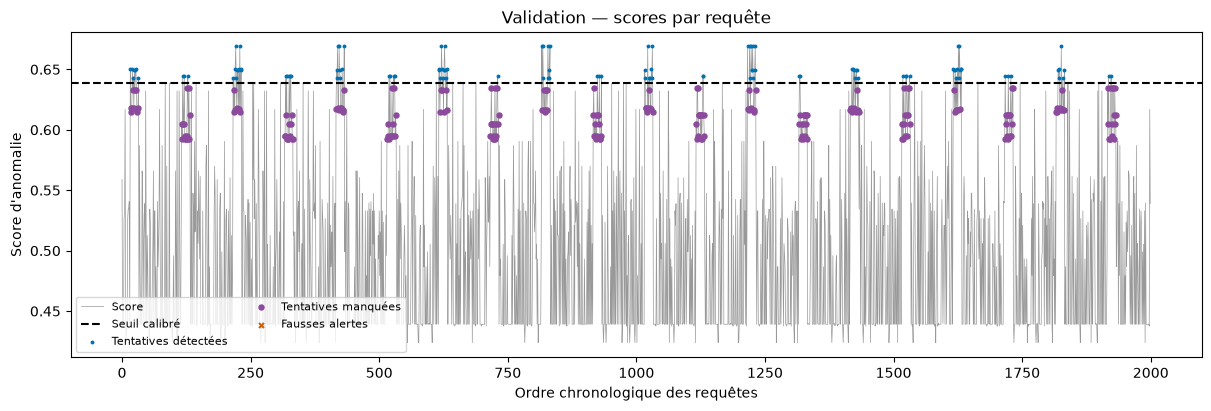

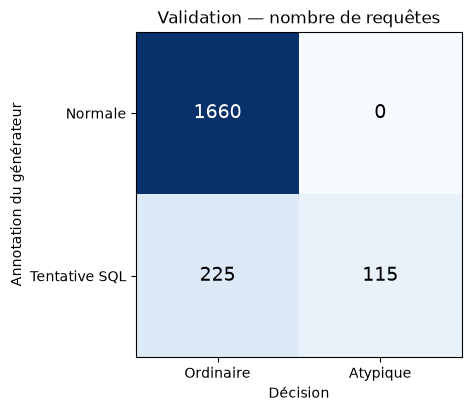

In [3]:
df = predictions["validation"].sort_values("observed_at").reset_index(drop=True)
y, p = df.is_attack.eq(1), df.predicted_anomaly.eq(1)
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
ax.plot(df.index, df.anomaly_score, color="#999999", lw=.5, label="Score")
ax.axhline(threshold, color="black", ls="--", label="Seuil calibré")
for mask, label, color, marker in [(y & p, "Tentatives détectées", "#0072B2", "."),
                                    (y & ~p, "Tentatives manquées", "#8B4A9C", "o"),
                                    (~y & p, "Fausses alertes", "#D55E00", "x")]:
    ax.scatter(df.index[mask], df.loc[mask, "anomaly_score"], label=label, color=color, marker=marker, s=13, zorder=3)
ax.set(title="Validation — scores par requête", xlabel="Ordre chronologique des requêtes", ylabel="Score d'anomalie")
ax.legend(loc="lower left", fontsize=8, ncol=2)
plt.show()

s = summary.loc["validation"]
cm = np.array([[s.VN, s.FP], [s.FN, s.VP]], dtype=int)
fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ax.imshow(cm, cmap="Blues")
for (i,j),value in np.ndenumerate(cm):
    ax.text(j,i,str(value),ha="center",va="center",fontsize=14,
            color="white" if value > cm.max()/2 else "black")
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=["Ordinaire", "Atypique"],
       yticklabels=["Normale", "Tentative SQL"],xlabel="Décision",ylabel="Annotation du générateur",
       title="Validation — nombre de requêtes")
plt.show()


## 3. Scénarios et épisodes

Un épisode est une session synthétique contenant des tentatives. Il est « détecté » si au moins une tentative est signalée. Le délai est calculé entre la première tentative de la session et la première tentative détectée ; ce n'est pas un délai de collecte Loki ou d'exécution en direct.


In [4]:
v = report["splits"]["validation"]
display(pd.DataFrame(v["by_scenario"]))
episodes = pd.DataFrame(v["episodes"])
print(f"Épisodes repérés : {int(episodes.detected.sum())}/{len(episodes)}")
print("Sessions entièrement normales ayant au moins une alerte :", v["normal_sessions_with_alert"])
display(episodes)


,scenario,attack_requests,detected_requests,recall
0,boolean,170,86,0.505882
1,union,170,29,0.170588


Épisodes repérés : 20/20
Sessions entièrement normales ayant au moins une alerte : 0


,session_id,scenario,attack_requests,detected_requests,detected,delay_seconds_observed
0,validation-0000,boolean,17,7,True,0.0
1,validation-0002,union,17,3,True,2.0
2,validation-0004,boolean,17,10,True,0.0
3,validation-0006,union,17,5,True,2.0
4,validation-0008,boolean,17,8,True,1.0
5,validation-0010,union,17,4,True,3.0
6,validation-0012,boolean,17,11,True,0.0
7,validation-0014,union,17,1,True,28.0
8,validation-0016,boolean,17,8,True,0.0
9,validation-0018,union,17,3,True,8.0


## 4. Examiner les tentatives manquées et les fausses alertes

Le décodage ci-dessous sert uniquement à lire les exemples. Les apostrophes, les espaces et l'encodage existent aussi dans les requêtes normales : ils ne suffisent pas seuls à affirmer une attaque.


In [5]:
columns = ["observed_at", "session_id", "scenario", "query", "anomaly_score"]
missed = df[y & ~p].copy()
false_alerts = df[~y & p].copy()
print("Tentatives manquées :", len(missed))
examples = missed.head(12)[columns].copy()
examples["query_decoded_for_reading"] = examples["query"].map(lambda value: unquote_plus(unquote_plus(value)))
display(examples)
print("Fausses alertes :", len(false_alerts))
display(false_alerts.head(12)[columns])


Tentatives manquées : 225


,observed_at,session_id,scenario,query,anomaly_score,query_decoded_for_reading
17,2026-11-02 16:01:25+00:00,validation-0000,boolean,q=FAILED%27%20AND%202%3D2%20--,0.614898,q=FAILED' AND 2=2 --
18,2026-11-02 16:01:30+00:00,validation-0000,boolean,q=SUCCESS%27+OR+1%3D1+--,0.618069,q=SUCCESS' OR 1=1 --
19,2026-11-02 16:01:35+00:00,validation-0000,boolean,q=SUCCESS%27+OR+1%3D1+--,0.618069,q=SUCCESS' OR 1=1 --
21,2026-11-02 16:01:45+00:00,validation-0000,boolean,q=%27%20OR%20%27a%27%3D%27a%27%20--,0.633340,q=' OR 'a'='a' --
23,2026-11-02 16:01:55+00:00,validation-0000,boolean,q=SUCCESS%27+OR+1%3D1+--,0.618069,q=SUCCESS' OR 1=1 --
25,2026-11-02 16:02:05+00:00,validation-0000,boolean,q=%27%20OR%20%27a%27%3D%27a%27%20--,0.633340,q=' OR 'a'='a' --
28,2026-11-02 16:02:20+00:00,validation-0000,boolean,q=%27%20OR%20%27a%27%3D%27a%27%20--,0.633340,q=' OR 'a'='a' --
29,2026-11-02 16:02:25+00:00,validation-0000,boolean,q=FAILED%27%20AND%202%3D2%20--,0.614898,q=FAILED' AND 2=2 --
30,2026-11-02 16:02:30+00:00,validation-0000,boolean,q=FAILED%27+AND+2%3D2+--,0.616822,q=FAILED' AND 2=2 --
31,2026-11-02 16:02:35+00:00,validation-0000,boolean,q=SUCCESS%27+OR+1%3D1+--,0.618069,q=SUCCESS' OR 1=1 --


Fausses alertes : 0


,observed_at,session_id,scenario,query,anomaly_score


## Limites à conserver dans l'interprétation

- Cet essai utilise un petit catalogue de requêtes normales rééchantillonnées : plusieurs milliers de lignes ne représentent pas plusieurs milliers de comportements distincts.
- Le générateur a été connu lors de la conception. Cette validation est exploratoire et ne démontre pas une généralisation aux attaques réelles.
- Les paramètres d'URL sont les seules entrées du modèle. IP, route, statut HTTP, taille de réponse, labels et noms des scénarios sont exclus. L'IP reste disponible pour rattacher l'observation à un client.
- Les corps POST, le contexte utilisateur, le rythme et les conséquences SQL ne sont pas analysés ici. Le double décodage est une représentation choisie, pas une garantie contre tous les encodages.
- Un seul candidat a été essayé avec les paramètres annoncés. Le quantile 99,5 % ne garantit pas un taux de fausses alertes de 0,5 % sur de nouvelles données.
- Pas de test scoré, pas de décision block_ip, pas d'appel incidents ou Ansible. Prévoir une évaluation réelle distincte avant automatisation.
